# Portuguese Bank Marketing Campaign Prediction
## End-to-End Machine Learning Project: EDA, Feature Engineering, Model Comparison, Hyperparameter Tuning & Deployment

**Dataset:** `bank-additional-full.csv`  
**Target:** `y` — whether a client subscribed to a term deposit (`yes` / `no`)  
**Objective:** Build a reproducible classification pipeline that helps a bank identify customers who are more likely to subscribe to a term deposit.

### Project workflow
Business understanding → data audit → EDA → preprocessing → feature engineering → stratified split → baseline models → tuning → top-three comparison → threshold analysis → interpretation → deployment-ready pipeline.

> **Important modelling decision:** `duration` is excluded from the primary model because call duration is only known after the phone call. Using it for a pre-call targeting decision would create information leakage. A separate post-call model could include it, but that is a different business use case.

## 1. Business understanding and success criteria

The target is imbalanced: in this dataset, customers who subscribe are a minority. Therefore, accuracy alone is not an adequate success metric.

We will:
- prioritize **F1-score** during model selection as a balance between precision and recall;
- also report precision, recall, ROC-AUC, PR-AUC, balanced accuracy and the confusion matrix;
- inspect the top three models selected by cross-validation, then evaluate each on the same untouched test set;
- keep preprocessing and feature engineering inside a single scikit-learn pipeline to prevent train/test leakage.

### Notes on the supplied review feedback
- This is a **bank marketing** dataset, not a heart-disease dataset. It contains no `thal` column, so `thal` ordinal encoding is not applicable.
- The supplied CSV has 41,188 rows, not 180 samples.
- We will document the categorical treatment of `month`, `day_of_week`, and `poutcome` explicitly.

## 2. Import libraries and configure reproducibility

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, balanced_accuracy_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
import joblib
import sklearn

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

pandas: 3.0.5
scikit-learn: 1.9.0


## 3. Load the actual uploaded dataset

In [3]:
# If running locally, keep bank-additional-full.csv in the same folder as this notebook.
# The official bank-additional-full.csv file is semicolon-separated.
DATA_PATH = "bank-additional-full.csv"

data = pd.read_csv(DATA_PATH, sep=";")

print("Dataset shape:", data.shape)
display(data.head())

Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 4. Data dictionary and initial audit

In [4]:
print("Columns:")
print(data.columns.tolist())

print("\\nData types and non-null counts:")
data.info()

display(data.describe(include="all").T)

Columns:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']
\nData types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 no

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,41188.0,NaN,NaN,NaN,40.02406,10.42125,17.0,32.0,38.0,47.0,98.0
job,41188,12,admin.,10422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,41188,4,married,24928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,41188,8,university.degree,12168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,41188,3,no,32588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,41188,3,yes,21576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,41188,3,no,33950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,41188,2,cellular,26144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,41188,10,may,13769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,41188,5,thu,8623,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
print("Missing values per column:")
display(data.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("Exact duplicate rows:", data.duplicated().sum())
print("\\nTarget distribution:")
display(data["y"].value_counts().to_frame("count"))
display((data["y"].value_counts(normalize=True) * 100).round(2).to_frame("percentage"))

Missing values per column:


,missing_count
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


Exact duplicate rows: 12
\nTarget distribution:


,count
y,
no,36548
yes,4640


,percentage
y,
no,88.73
yes,11.27


### Dataset-specific observations
The dataset includes demographic/customer fields (`age`, `job`, `marital`, `education`), existing product/credit fields (`default`, `housing`, `loan`), campaign contact fields (`contact`, `month`, `day_of_week`, `campaign`, `pdays`, `previous`, `poutcome`), and macroeconomic indicators.

In this dataset, `pdays = 999` is a special value meaning the client was not previously contacted in an earlier campaign. We will preserve that information with a separate indicator and convert the sentinel to missing before imputation.

## 5. Data cleaning

In [6]:
data = data.copy()

# Normalize target labels and remove rows with an unusable target.
data["y"] = data["y"].astype(str).str.strip().str.lower()
data = data[data["y"].isin(["yes", "no"])].copy()

# Remove exact duplicate records, if any.
data = data.drop_duplicates().reset_index(drop=True)

# Check for unexpected values.
for col in data.select_dtypes(include="object").columns:
    data[col] = data[col].astype(str).str.strip()

print("Cleaned shape:", data.shape)
print(data["y"].value_counts(normalize=True).round(4))

Cleaned shape: (41176, 21)
y
no     0.8873
yes    0.1127
Name: proportion, dtype: float64


## 6. Exploratory data analysis (EDA)

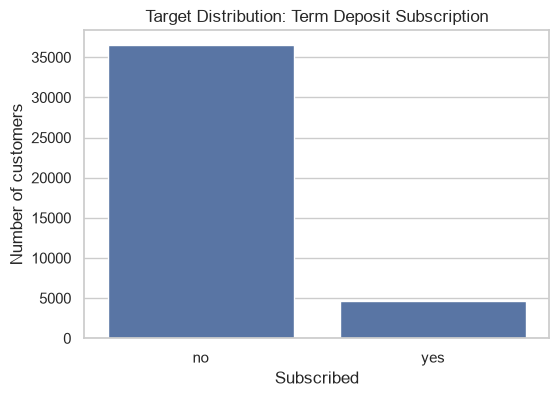

In [7]:
plt.figure(figsize=(6, 4))
sns.countplot(data=data, x="y", order=["no", "yes"])
plt.title("Target Distribution: Term Deposit Subscription")
plt.xlabel("Subscribed")
plt.ylabel("Number of customers")
plt.show()

In [8]:
# Numerical descriptive statistics
numeric_eda = data.select_dtypes(include=np.number).describe().T
display(numeric_eda)

,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.023800,10.420680,17.000,32.000,38.000,47.000,98.000
duration,41176.0,258.315815,259.305321,0.000,102.000,180.000,319.000,4918.000
campaign,41176.0,2.567879,2.770318,1.000,1.000,2.000,3.000,56.000
pdays,41176.0,962.464810,186.937102,0.000,999.000,999.000,999.000,999.000
previous,41176.0,0.173013,0.494964,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41176.0,0.081922,1.570883,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41176.0,93.575720,0.578839,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41176.0,-40.502863,4.627860,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41176.0,3.621293,1.734437,0.634,1.344,4.857,4.961,5.045
nr.employed,41176.0,5167.034870,72.251364,4963.600,5099.100,5191.000,5228.100,5228.100


In [9]:
# Compare numerical feature summaries across target classes.
numeric_cols_eda = data.select_dtypes(include=np.number).columns.tolist()
class_summary = data.groupby("y")[numeric_cols_eda].agg(["mean", "median", "std"]).T
display(class_summary)

y                               no          yes
age            mean      39.910994    40.912266
               median    38.000000    37.000000
               std        9.897176    13.838838
duration       mean     220.868079   553.256090
               median   164.000000   449.000000
               std      207.116178   401.190736
campaign       mean       2.633385     2.051951
               median     2.000000     2.000000
               std        2.873768     1.666353
pdays          mean     984.109396   791.990946
               median   999.000000   999.000000
               std      120.674753   403.439220
previous       mean       0.132414     0.492779
               median     0.000000     0.000000
               std        0.409254     0.860406
emp.var.rate   mean       0.248885    -1.233089
               median     1.100000    -1.800000
               std        1.482873     1.623616
cons.price.idx mean      93.603798    93.354577
               median    93.918000    93.200000
               std        0.559006     0.676592
cons.conf.idx  mean     -40.593232   -39.791119
               median   -41.800000   -40.400000
               std        4.390759     6.139657
euribor3m      mean       3.811482     2.123362
               median     4.857000     1.266000
               std        1.638179     1.742717
nr.employed    mean    5176.165690  5095.120069
               median  5195.800000  5099.100000
               std       64.570288    87.581640

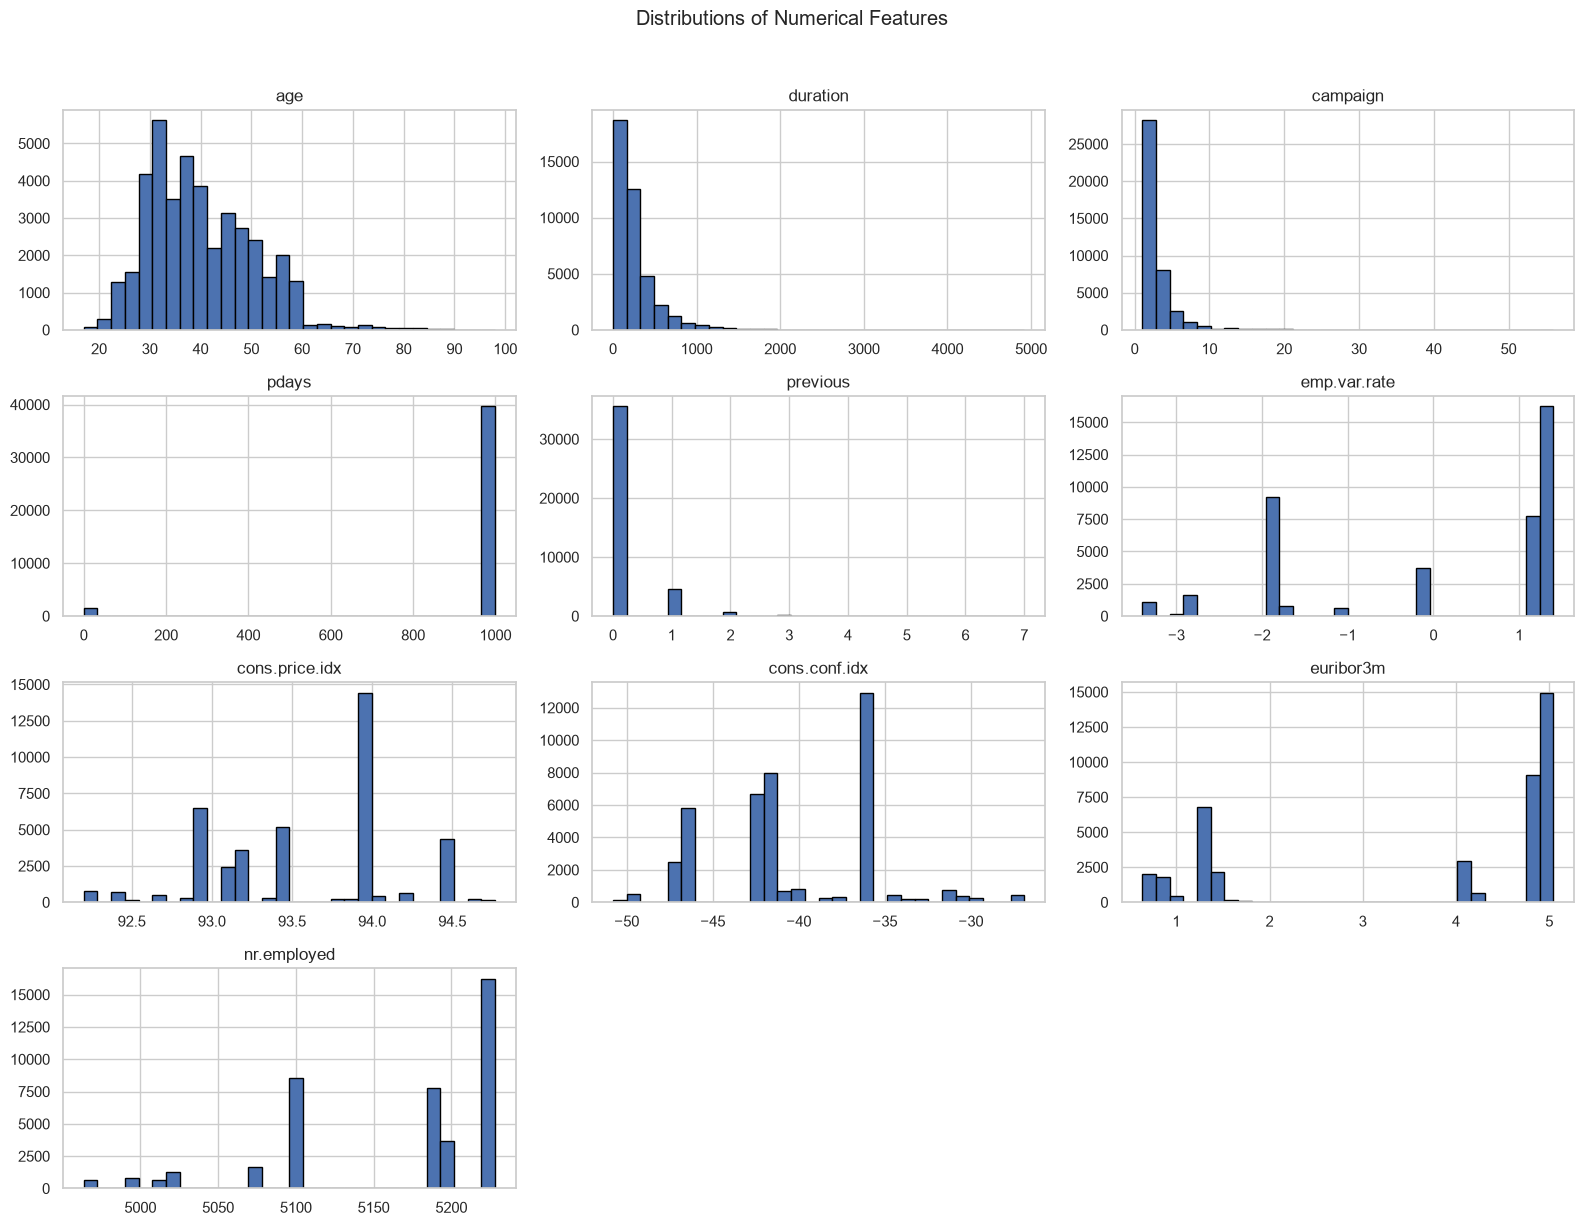

In [10]:
# Histograms for numerical features
data[numeric_cols_eda].hist(figsize=(16, 12), bins=30, edgecolor="black")
plt.suptitle("Distributions of Numerical Features", y=1.02)
plt.tight_layout()
plt.show()

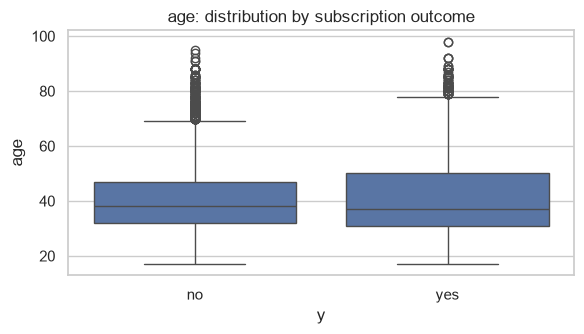

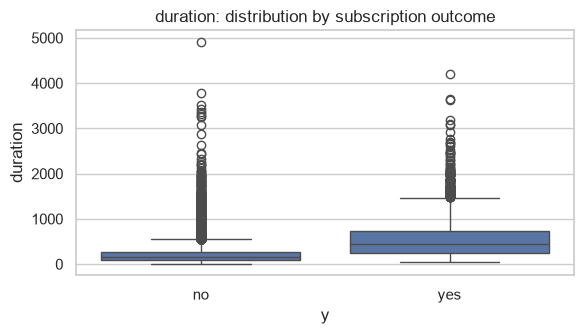

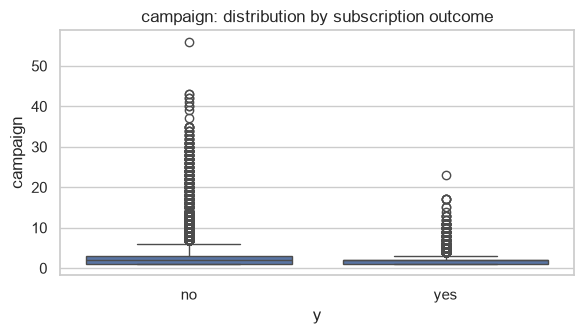

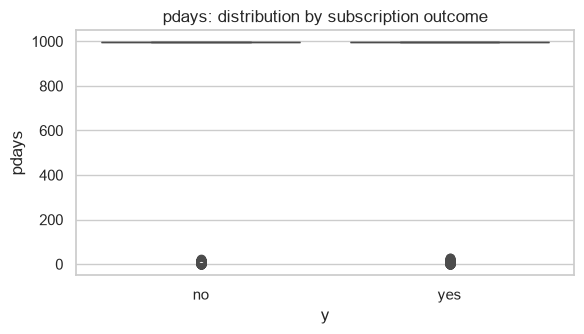

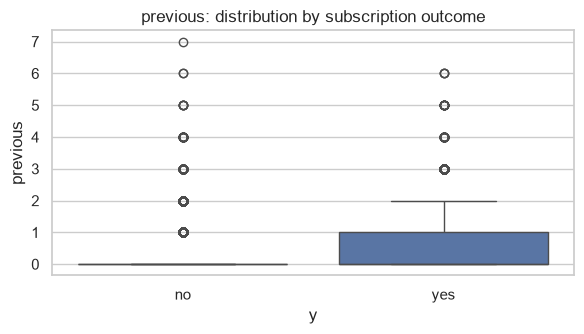

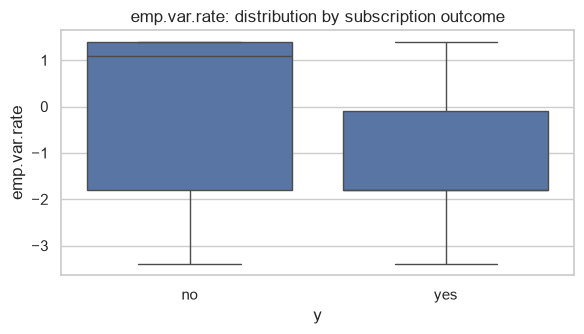

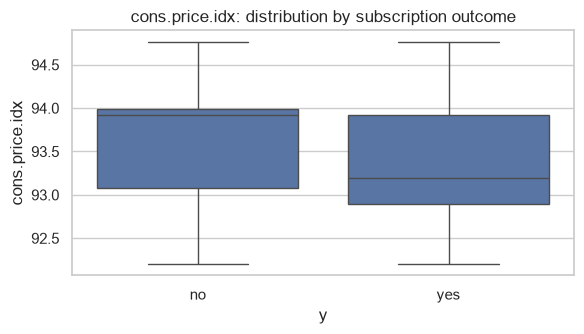

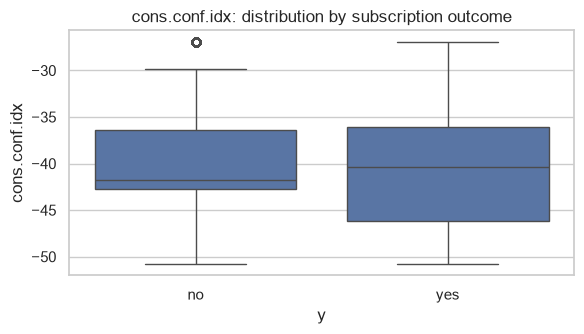

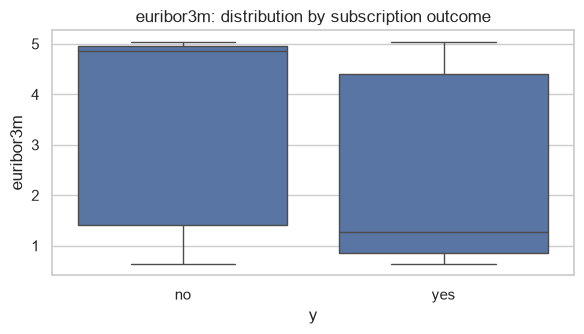

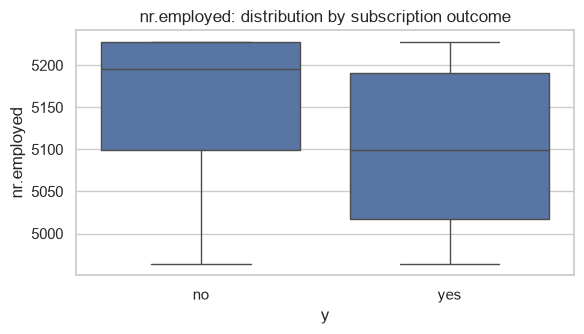

In [11]:
# Box plots: numerical features by target class
for col in numeric_cols_eda:
    plt.figure(figsize=(6, 3.5))
    sns.boxplot(data=data, x="y", y=col, order=["no", "yes"])
    plt.title(f"{col}: distribution by subscription outcome")
    plt.tight_layout()
    plt.show()

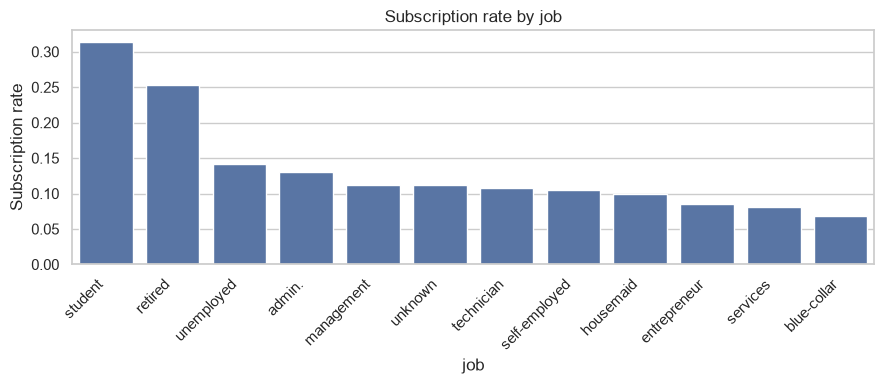

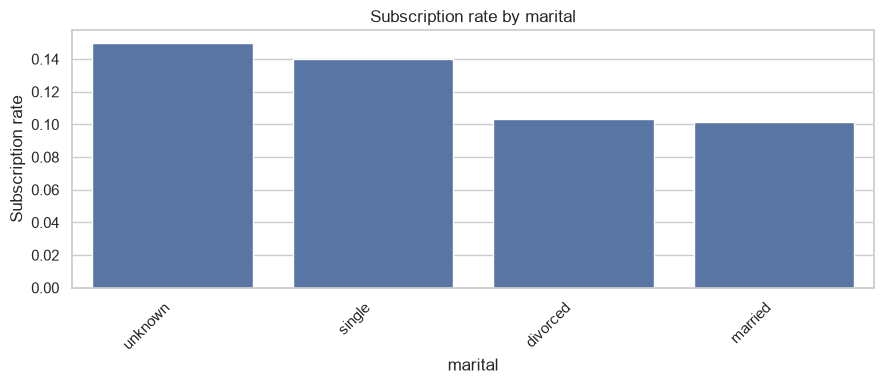

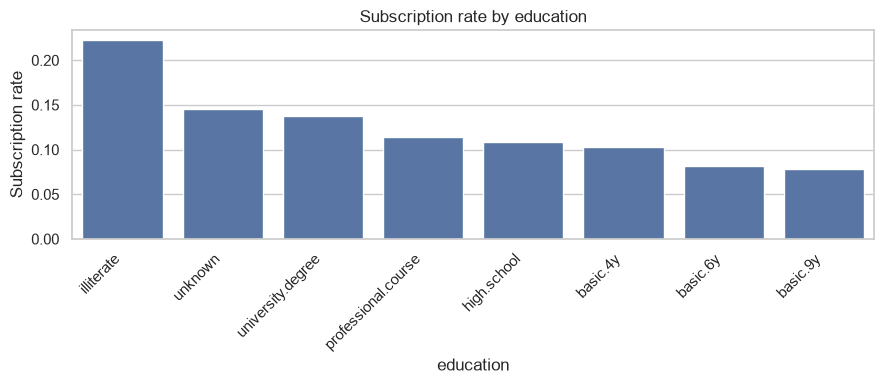

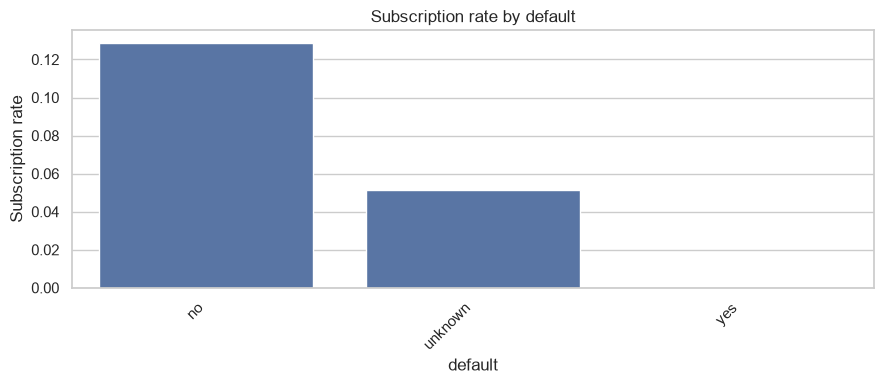

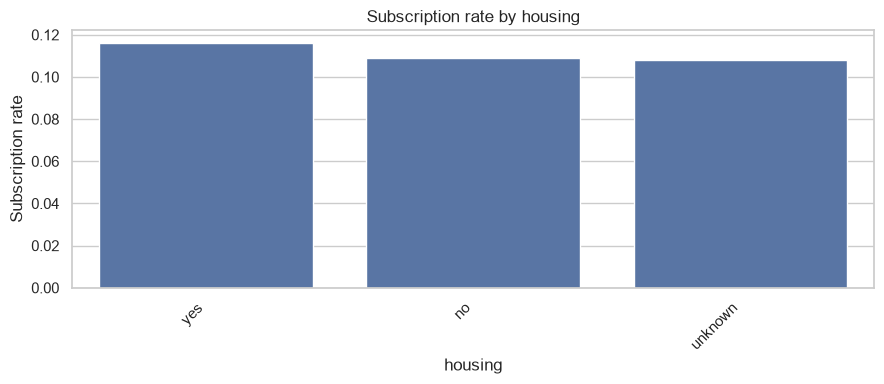

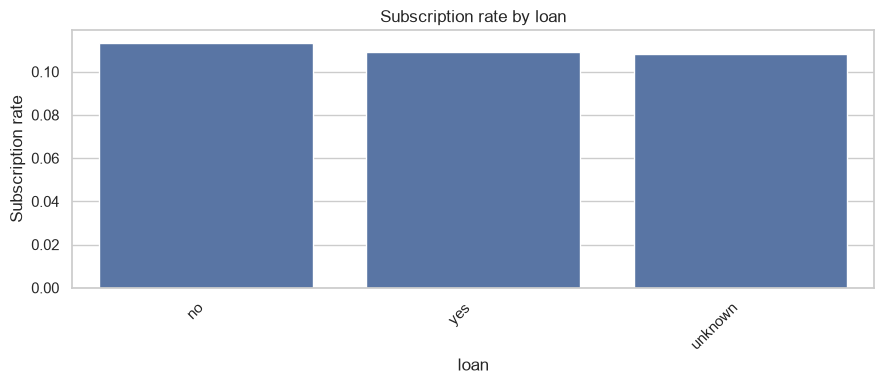

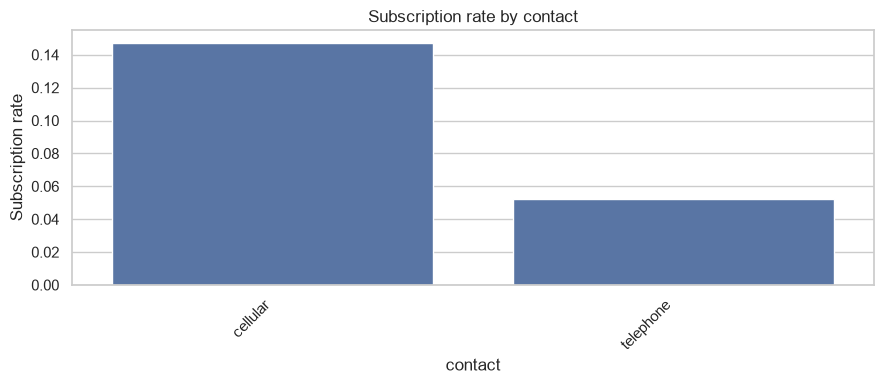

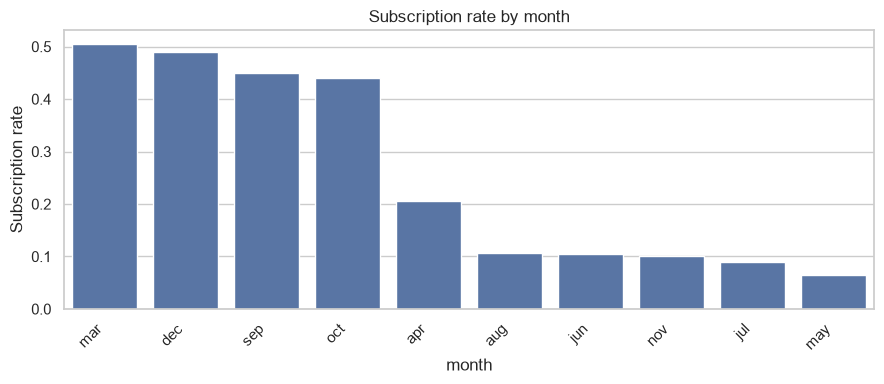

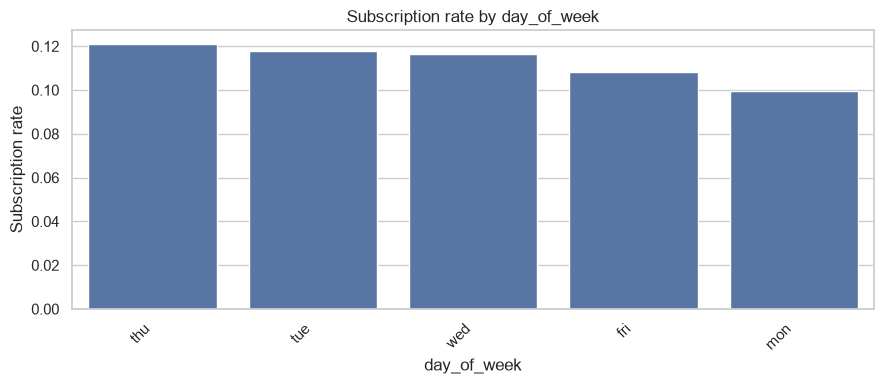

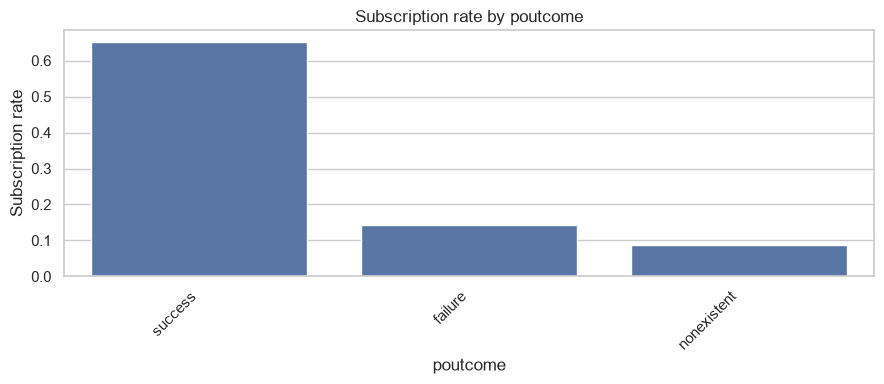

In [12]:
# Categorical subscription rates
categorical_eda = data.select_dtypes(include="object").columns.drop("y").tolist()

for col in categorical_eda:
    rate = data.groupby(col, dropna=False)["y"].apply(lambda s: (s == "yes").mean()).sort_values(ascending=False)
    plt.figure(figsize=(9, 4))
    sns.barplot(x=rate.index.astype(str), y=rate.values)
    plt.title(f"Subscription rate by {col}")
    plt.ylabel("Subscription rate")
    plt.xlabel(col)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

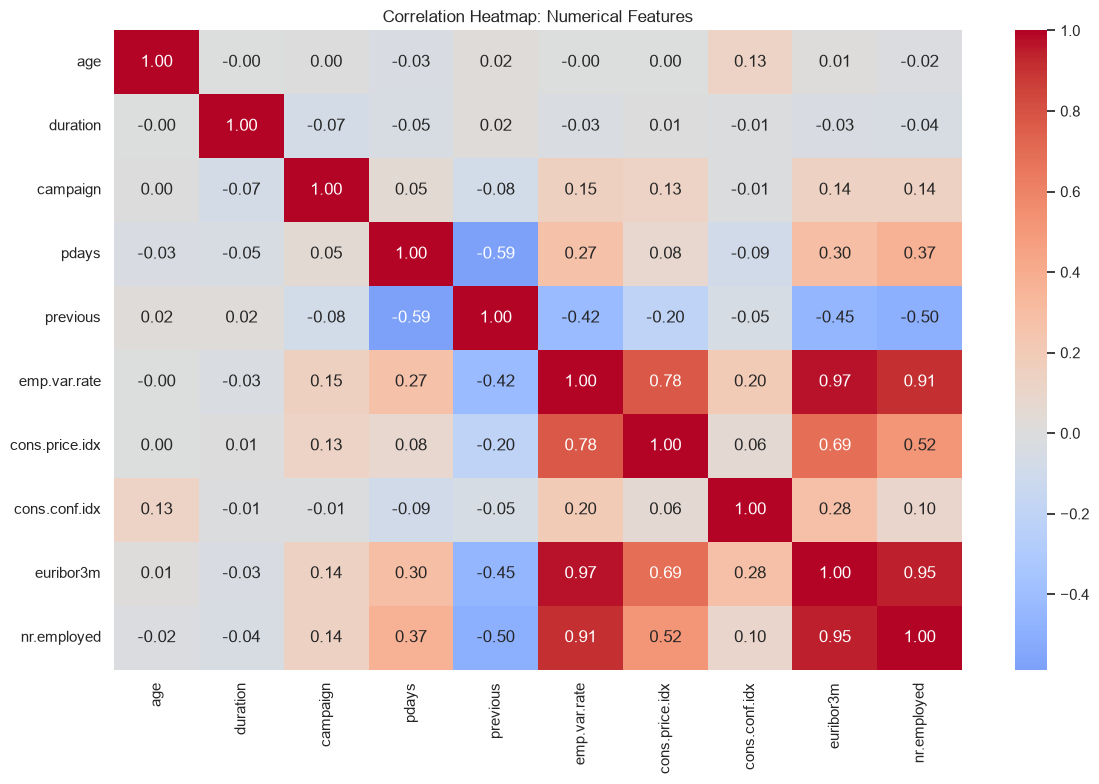

In [13]:
plt.figure(figsize=(12, 8))
corr = data.select_dtypes(include=np.number).corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation Heatmap: Numerical Features")
plt.tight_layout()
plt.show()

### EDA interpretation checklist
When reviewing the charts, document:
1. the size of the class imbalance and why accuracy can be misleading;
2. numerical features whose mean/median differ between subscribers and non-subscribers;
3. categories with notably different subscription rates;
4. possible outliers and skewed distributions;
5. correlations among macroeconomic indicators.

Do not interpret association as causation. Campaign outcomes can also be affected by the historical campaign strategy and the time period represented in the data.

## 7. Define target and prevent information leakage

In [14]:
# Target: yes = 1, no = 0
y = data["y"].map({"no": 0, "yes": 1}).astype(int)

# duration is deliberately excluded: it is only known after the call.
X = data.drop(columns=["y", "duration"])

print("Feature matrix:", X.shape)
print("Target balance:")
display(y.value_counts(normalize=True).rename("proportion"))

Feature matrix: (41176, 19)
Target balance:


y
0    0.887337
1    0.112663
Name: proportion, dtype: float64

## 8. Feature engineering

We use deterministic, row-level transformations that do not learn statistics from the full dataset:
- `was_previously_contacted`: whether `pdays` is not the 999 sentinel;
- `pdays` 999 is replaced by missing so the imputer can handle it;
- `campaign_log`: log-transformed contact count;
- `previous_contact_log`: log-transformed number of earlier contacts;
- `age_group`: broad age bands;
- `month_num`, `month_sin`, `month_cos`: calendar month representation;
- `day_num`, `day_sin`, `day_cos`: weekday representation.

`month` and `day_of_week` are transformed into cyclical numeric features and removed from the categorical inputs. Other nominal variables, including `job`, `marital`, `education`, `contact`, and `poutcome`, are one-hot encoded. We do not impose an artificial ordinal ranking on `poutcome`; `success`, `failure`, and `nonexistent` are states, not a universally meaningful ordered scale.

In [15]:
class BankFeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.month_map = {
            "jan": 1, "feb": 2, "mar": 3, "apr": 4, "may": 5, "jun": 6,
            "jul": 7, "aug": 8, "sep": 9, "oct": 10, "nov": 11, "dec": 12
        }
        self.day_map = {"mon": 0, "tue": 1, "wed": 2, "thu": 3, "fri": 4}

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        if "pdays" in X.columns:
            X["was_previously_contacted"] = (X["pdays"] != 999).astype(int)
            X["pdays"] = X["pdays"].replace(999, np.nan)

        if "campaign" in X.columns:
            X["campaign_log"] = np.log1p(X["campaign"].clip(lower=0))

        if "previous" in X.columns:
            X["previous_contact_log"] = np.log1p(X["previous"].clip(lower=0))

        if "age" in X.columns:
            X["age_group"] = pd.cut(
                X["age"], bins=[0, 25, 35, 45, 55, 65, 120],
                labels=["18-25", "26-35", "36-45", "46-55", "56-65", "65+"],
                include_lowest=True
            ).astype("object")

        if "month" in X.columns:
            month_num = X["month"].astype(str).str.lower().map(self.month_map)
            X["month_num"] = month_num
            X["month_sin"] = np.sin(2 * np.pi * month_num / 12)
            X["month_cos"] = np.cos(2 * np.pi * month_num / 12)
            X = X.drop(columns=["month"])

        if "day_of_week" in X.columns:
            day_num = X["day_of_week"].astype(str).str.lower().map(self.day_map)
            X["day_num"] = day_num
            X["day_sin"] = np.sin(2 * np.pi * day_num / 5)
            X["day_cos"] = np.cos(2 * np.pi * day_num / 5)
            X = X.drop(columns=["day_of_week"])

        return X

In [16]:
feature_engineer = BankFeatureEngineer()
X_engineered_preview = feature_engineer.fit_transform(X)

print("Original feature count:", X.shape[1])
print("After feature engineering:", X_engineered_preview.shape[1])
display(X_engineered_preview.head())

Original feature count: 19
After feature engineering: 27


,age,job,marital,education,default,housing,loan,contact,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,was_previously_contacted,campaign_log,previous_contact_log,age_group,month_num,month_sin,month_cos,day_num,day_sin,day_cos
0,56,housemaid,married,basic.4y,no,no,no,telephone,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0.693147,0.0,56-65,5,0.5,-0.866025,0,0.0,1.0
1,57,services,married,high.school,unknown,no,no,telephone,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0.693147,0.0,56-65,5,0.5,-0.866025,0,0.0,1.0
2,37,services,married,high.school,no,yes,no,telephone,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0.693147,0.0,36-45,5,0.5,-0.866025,0,0.0,1.0
3,40,admin.,married,basic.6y,no,no,no,telephone,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0.693147,0.0,36-45,5,0.5,-0.866025,0,0.0,1.0
4,56,services,married,high.school,no,no,yes,telephone,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0.693147,0.0,56-65,5,0.5,-0.866025,0,0.0,1.0


## 9. Stratified train-test split

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train positive rate:", round(y_train.mean(), 4))
print("Test positive rate:", round(y_test.mean(), 4))

Train: (32940, 19)  Test: (8236, 19)
Train positive rate: 0.1127
Test positive rate: 0.1127


The split is stratified so the minority-class proportion is approximately preserved in both partitions. The test set is held back until model selection and tuning are complete. All learned preprocessing (imputation, scaling, encoding) is fitted inside the pipeline using training folds only.

## 10. Preprocessing pipeline

In [18]:
# Determine transformed column groups from the training data after feature engineering.
X_train_fe = feature_engineer.fit_transform(X_train)
numeric_features = X_train_fe.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train_fe.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
], remainder="drop")

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'was_previously_contacted', 'campaign_log', 'previous_contact_log', 'month_num', 'month_sin', 'month_cos', 'day_num', 'day_sin', 'day_cos']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'poutcome', 'age_group']


## 11. Baseline models

In [19]:
baseline_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, class_weight="balanced_subsample",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=250, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        random_state=RANDOM_STATE
    )
}

baseline_results = []
baseline_pipelines = {}

for name, estimator in baseline_models.items():
    pipe = Pipeline(steps=[
        ("feature_engineering", BankFeatureEngineer()),
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else None

    baseline_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba) if proba is not None else np.nan,
        "PR-AUC": average_precision_score(y_test, proba) if proba is not None else np.nan
    })
    baseline_pipelines[name] = pipe

baseline_results_df = pd.DataFrame(baseline_results).sort_values("F1", ascending=False)
display(baseline_results_df)

,Model,Accuracy,Precision,Recall,F1,Balanced Accuracy,ROC-AUC,PR-AUC
0,Logistic Regression,0.822001,0.347159,0.658405,0.454613,0.750590,0.797444,0.445893
2,Random Forest,0.894123,0.561404,0.275862,0.369942,0.624247,0.783172,0.430643
3,Extra Trees,0.884896,0.482517,0.297414,0.368000,0.628455,0.751517,0.348536
4,Hist Gradient Boosting,0.900073,0.648725,0.246767,0.357533,0.614900,0.814500,0.496412
1,Decision Tree,0.847984,0.332645,0.346983,0.339662,0.629293,0.629619,0.190686


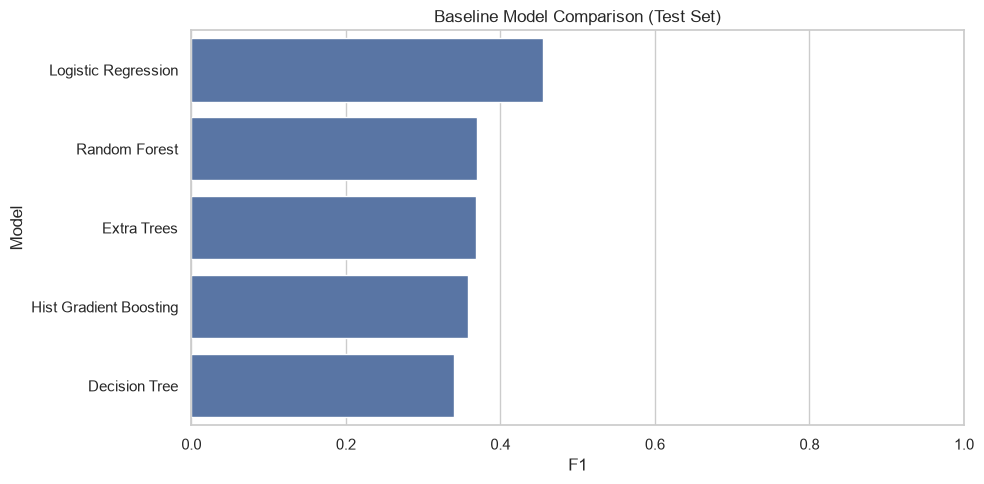

In [20]:
plt.figure(figsize=(10, 5))
sns.barplot(data=baseline_results_df, x="F1", y="Model")
plt.title("Baseline Model Comparison (Test Set)")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

## 12. Hyperparameter tuning with GridSearchCV

We tune several different model families using stratified cross-validation and F1 as the primary selection metric. The grids are intentionally practical; expanding them substantially can increase runtime. `n_jobs=-1` uses available CPU cores.

The feature-engineering step remains inside every candidate pipeline. This prevents the final model from silently reverting to `passthrough`.

In [21]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

tuning_spaces = {
    "Logistic Regression": (
        LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE),
        {
            "model__C": [0.1, 1.0, 3.0],
            "model__solver": ["liblinear"]
        }
    ),
    "Decision Tree": (
        DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        {
            "model__max_depth": [4, 8, 12, None],
            "model__min_samples_leaf": [5, 15, 30]
        }
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1),
        {
            "model__n_estimators": [200, 350],
            "model__max_depth": [8, 16, None],
            "model__min_samples_leaf": [2, 5]
        }
    ),
    "Extra Trees": (
        ExtraTreesClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
        {
            "model__n_estimators": [200, 350],
            "model__max_depth": [8, 16, None],
            "model__min_samples_leaf": [2, 5]
        }
    )
}

searches = {}
tuning_rows = []

for name, (estimator, param_grid) in tuning_spaces.items():
    pipe = Pipeline(steps=[
        ("feature_engineering", BankFeatureEngineer()),
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    search = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1,
        return_train_score=True
    )
    search.fit(X_train, y_train)
    searches[name] = search

    tuning_rows.append({
        "Model": name,
        "Best CV F1": search.best_score_,
        "Best Parameters": search.best_params_
    })

tuning_results = pd.DataFrame(tuning_rows).sort_values("Best CV F1", ascending=False)
display(tuning_results)

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Fitting 3 folds for each of 12 candidates, totalling 36 fits


,Model,Best CV F1,Best Parameters
2,Random Forest,0.497151,"{'model__max_depth': None, 'model__min_samples..."
3,Extra Trees,0.478921,"{'model__max_depth': 16, 'model__min_samples_l..."
1,Decision Tree,0.453819,"{'model__max_depth': 4, 'model__min_samples_le..."
0,Logistic Regression,0.440447,"{'model__C': 3.0, 'model__solver': 'liblinear'}"


## 13. Compare the top three tuned models on the same test set

In [22]:
# Rank models by cross-validation F1, not by test-set performance.
top_three_names = tuning_results.head(3)["Model"].tolist()
print("Top three models selected using CV F1:", top_three_names)

top_three_results = []
top_three_fitted = {}

for name in top_three_names:
    best_pipe = searches[name].best_estimator_
    top_three_fitted[name] = best_pipe

    pred = best_pipe.predict(X_test)
    proba = best_pipe.predict_proba(X_test)[:, 1]

    top_three_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "PR-AUC": average_precision_score(y_test, proba)
    })

top_three_df = pd.DataFrame(top_three_results).sort_values("F1", ascending=False)
display(top_three_df)

Top three models selected using CV F1: ['Random Forest', 'Extra Trees', 'Decision Tree']


,Model,Accuracy,Precision,Recall,F1,Balanced Accuracy,ROC-AUC,PR-AUC
0,Random Forest,0.875425,0.459967,0.606681,0.523234,0.758116,0.805832,0.487524
1,Extra Trees,0.864376,0.427252,0.598060,0.498428,0.748127,0.803474,0.469375
2,Decision Tree,0.842885,0.380392,0.627155,0.473556,0.748717,0.785986,0.411949


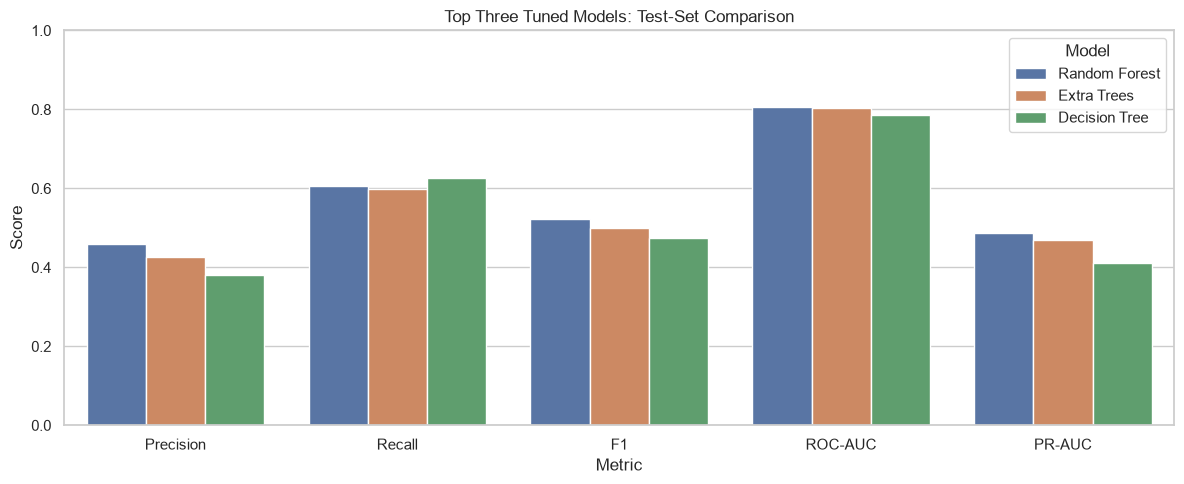

In [23]:
metrics_to_plot = ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
top_three_long = top_three_df.melt(
    id_vars="Model", value_vars=metrics_to_plot,
    var_name="Metric", value_name="Score"
)
plt.figure(figsize=(12, 5))
sns.barplot(data=top_three_long, x="Metric", y="Score", hue="Model")
plt.ylim(0, 1)
plt.title("Top Three Tuned Models: Test-Set Comparison")
plt.tight_layout()
plt.show()

## 14. Detailed evaluation of the selected model

In [29]:
# Select the model using cross-validation F1.
best_model_name = tuning_results.iloc[0]["Model"]
best_model = searches[best_model_name].best_estimator_

print("Selected model:", best_model_name)
print("Best CV F1:", round(searches[best_model_name].best_score_, 4))

y_test_pred = best_model.predict(X_test)
y_test_proba = best_model.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test, y_test_pred,
    target_names=["No subscription", "Subscription"],
    zero_division=0
))

Selected model: Random Forest
Best CV F1: 0.4972
                 precision    recall  f1-score   support

No subscription       0.95      0.91      0.93      7308
   Subscription       0.46      0.61      0.52       928

       accuracy                           0.88      8236
      macro avg       0.70      0.76      0.73      8236
   weighted avg       0.89      0.88      0.88      8236



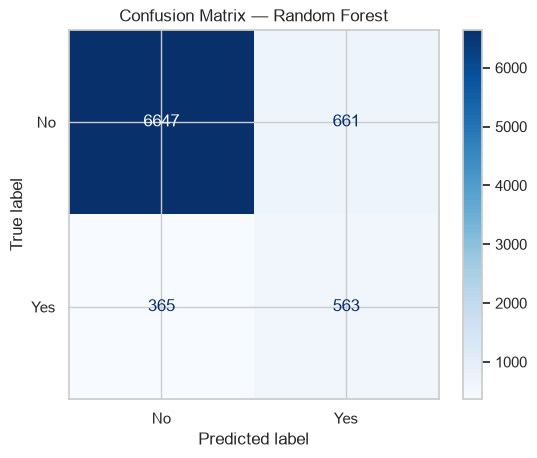

In [25]:
cm = confusion_matrix(y_test, y_test_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
).plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.show()

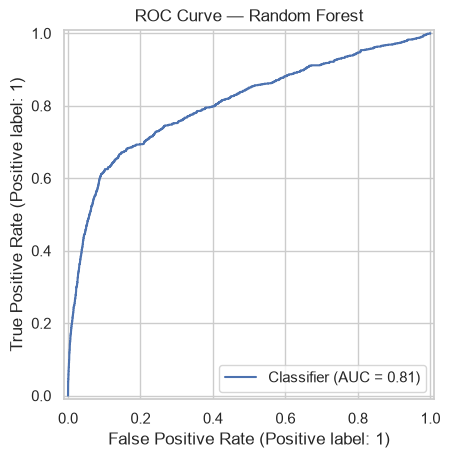

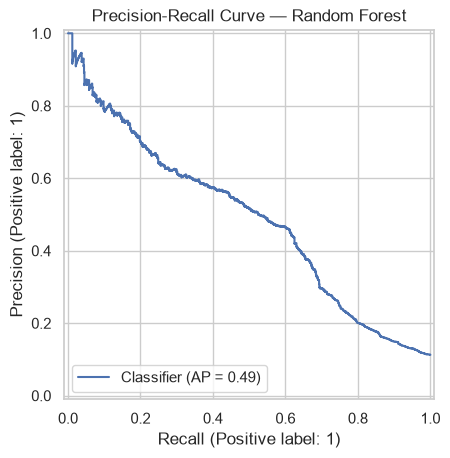

In [26]:
RocCurveDisplay.from_predictions(y_test, y_test_proba)
plt.title(f"ROC Curve — {best_model_name}")
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, y_test_proba)
plt.title(f"Precision-Recall Curve — {best_model_name}")
plt.show()

## 15. Decision-threshold analysis

The default classifier threshold is usually 0.50. For an imbalanced marketing problem, a different threshold may improve the precision/recall trade-off.

For a rigorous threshold choice, create a validation split from the training data, fit the selected hyperparameters on the smaller training portion, and choose the threshold using validation predictions. The test set remains untouched for the final one-time evaluation.

In [34]:

# Split training data into fit and validation subsets
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train
)

# Retrieve the best model from GridSearchCV
validation_model = searches[best_model_name].best_estimator_

# Fit the selected model on the fit subset
validation_model.fit(X_fit, y_fit)

# Predict probabilities on validation data
valid_proba = validation_model.predict_proba(X_valid)[:, 1]

# Evaluate different classification thresholds
threshold_rows = []

for threshold in np.arange(0.10, 0.91, 0.02):
    valid_pred = (valid_proba >= threshold).astype(int)

    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(
            y_valid, valid_pred, zero_division=0
        ),
        "recall": recall_score(
            y_valid, valid_pred, zero_division=0
        ),
        "f1": f1_score(
            y_valid, valid_pred, zero_division=0
        )
    })

# Create threshold comparison DataFrame
threshold_df = pd.DataFrame(threshold_rows)

display(
    threshold_df.sort_values(
        "f1", ascending=False
    ).head(10)
)

# Select the best threshold based on F1 score
best_threshold = float(
    threshold_df.loc[
        threshold_df["f1"].idxmax(), "threshold"
    ]
)

print("Validation-selected threshold:", round(best_threshold, 2))


,threshold,precision,recall,f1
23,0.56,0.483001,0.555256,0.516614
22,0.54,0.470852,0.566038,0.514076
24,0.58,0.488998,0.539084,0.512821
20,0.50,0.453403,0.583558,0.510312
19,0.48,0.446247,0.592992,0.509259
26,0.62,0.510176,0.506739,0.508452
21,0.52,0.456897,0.571429,0.507784
18,0.46,0.438545,0.601078,0.507106
25,0.60,0.493557,0.516173,0.504611
27,0.64,0.522562,0.483827,0.502449


Validation-selected threshold: 0.56


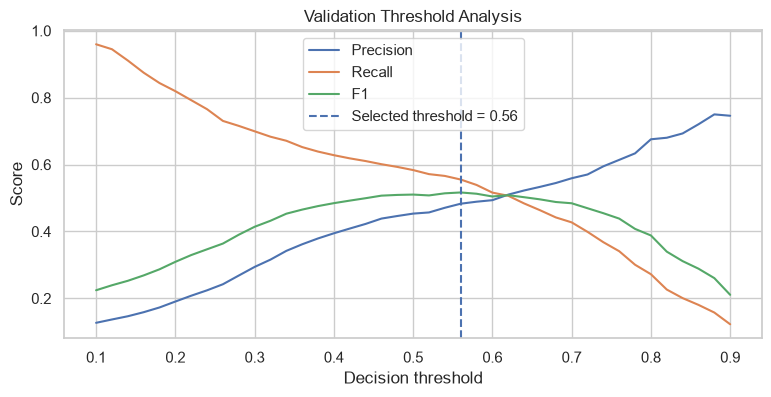

In [36]:
plt.figure(figsize=(9, 4))
plt.plot(threshold_df["threshold"], threshold_df["precision"], label="Precision")
plt.plot(threshold_df["threshold"], threshold_df["recall"], label="Recall")
plt.plot(threshold_df["threshold"], threshold_df["f1"], label="F1")
plt.axvline(best_threshold, linestyle="--", label=f"Selected threshold = {best_threshold:.2f}")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Validation Threshold Analysis")
plt.legend()
plt.show()

In [37]:
# Final test evaluation at the validation-selected threshold.
test_pred_tuned_threshold = (y_test_proba >= best_threshold).astype(int)

print("Test metrics at validation-selected threshold")
print("Precision:", precision_score(y_test, test_pred_tuned_threshold, zero_division=0))
print("Recall:", recall_score(y_test, test_pred_tuned_threshold, zero_division=0))
print("F1:", f1_score(y_test, test_pred_tuned_threshold, zero_division=0))
print("Confusion matrix:\\n", confusion_matrix(y_test, test_pred_tuned_threshold))

Test metrics at validation-selected threshold
Precision: 0.47714808043875684
Recall: 0.5625
F1: 0.516320474777448
Confusion matrix:\n [[6736  572]
 [ 406  522]]


## 16. Feature importance and interpretability

For a model-agnostic view, permutation importance measures how much the fitted model's score changes when a feature is shuffled. We compute it on the held-out test set for interpretation only; it is not used to tune or select the model.

The permutation importance is calculated on the raw input columns, so it can be interpreted at the original feature level, before one-hot expansion.

,Feature,Importance Mean,Importance Std
8,month,0.022964,0.001987
18,nr.employed,0.016463,0.003140
17,euribor3m,0.016269,0.002720
7,contact,0.014828,0.004994
11,pdays,0.005395,0.001215
14,emp.var.rate,0.004479,0.003803
9,day_of_week,0.003128,0.003637
15,cons.price.idx,0.002584,0.002005
4,default,0.001802,0.001779
10,campaign,0.001726,0.000555


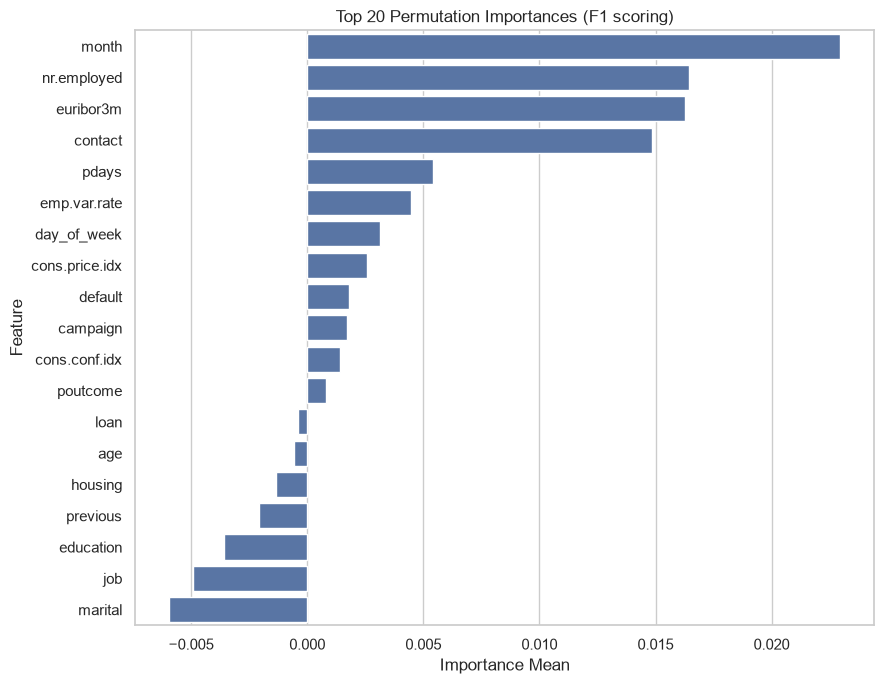

In [39]:
perm = permutation_importance(
    best_model, X_test, y_test,
    scoring="f1", n_repeats=5,
    random_state=RANDOM_STATE, n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": perm.importances_mean,
    "Importance Std": perm.importances_std
}).sort_values("Importance Mean", ascending=False)

display(importance_df.head(20))

plt.figure(figsize=(9, 7))
sns.barplot(data=importance_df.head(20), x="Importance Mean", y="Feature")
plt.title("Top 20 Permutation Importances (F1 scoring)")
plt.tight_layout()
plt.show()

## 17. Prompt engineering for campaign decision support

Prompt engineering is not a replacement for the trained classifier. The classifier produces probabilities and predictions; a language model can optionally turn validated outputs into a concise explanation for a campaign analyst.

The following is a **prompt template** that can be used with an approved enterprise LLM. It is deliberately grounded in model outputs, requests uncertainty disclosure, and prohibits unsupported causal claims. Do not send personally identifiable customer data to an external LLM unless the bank's privacy and security policies explicitly permit it.

In [42]:
campaign_insight_prompt = '''
Role:
You are a cautious banking campaign analytics assistant.

Task:
Explain the supplied aggregate model evaluation and feature-importance results
to a marketing manager. Recommend how the bank could use the model to
prioritize campaign outreach.

Context:
- Model: {model_name}
- Evaluation metrics: {metrics}
- Decision threshold: {threshold}
- Important features: {feature_importance}
- Business objective: identify customers who may be more likely to subscribe
  to a term deposit.

Requirements:
1. Explain precision and recall in plain language.
2. Explain the trade-off created by the selected decision threshold.
3. Distinguish predictive association from causation.
4. Mention class imbalance and the limits of the dataset.
5. Do not invent statistics or claim that a feature causes subscription.
6. Do not make a final financial decision about an individual customer.
7. Return: Executive summary, model limitations, campaign use, and monitoring plan.

Use only the facts provided above. If a value is missing, say it is unavailable.
'''

print(campaign_insight_prompt)


Role:
You are a cautious banking campaign analytics assistant.

Task:
Explain the supplied aggregate model evaluation and feature-importance results
to a marketing manager. Recommend how the bank could use the model to
prioritize campaign outreach.

Context:
- Model: {model_name}
- Evaluation metrics: {metrics}
- Decision threshold: {threshold}
- Important features: {feature_importance}
- Business objective: identify customers who may be more likely to subscribe
  to a term deposit.

Requirements:
1. Explain precision and recall in plain language.
2. Explain the trade-off created by the selected decision threshold.
3. Distinguish predictive association from causation.
4. Mention class imbalance and the limits of the dataset.
5. Do not invent statistics or claim that a feature causes subscription.
6. Do not make a final financial decision about an individual customer.
7. Return: Executive summary, model limitations, campaign use, and monitoring plan.

Use only the facts provided above.

In [43]:
# Populate the prompt with actual project outputs.
metrics_for_prompt = top_three_df.to_dict(orient="records")
features_for_prompt = importance_df.head(10).to_dict(orient="records")

filled_prompt = campaign_insight_prompt.format(
    model_name=best_model_name,
    metrics=metrics_for_prompt,
    threshold=round(best_threshold, 3),
    feature_importance=features_for_prompt
)
print(filled_prompt)


Role:
You are a cautious banking campaign analytics assistant.

Task:
Explain the supplied aggregate model evaluation and feature-importance results
to a marketing manager. Recommend how the bank could use the model to
prioritize campaign outreach.

Context:
- Model: Random Forest
- Evaluation metrics: [{'Model': 'Random Forest', 'Accuracy': 0.8754249635745508, 'Precision': 0.4599673202614379, 'Recall': 0.6066810344827587, 'F1': 0.5232342007434945, 'Balanced Accuracy': 0.7581161056376574, 'ROC-AUC': 0.8058315137638488, 'PR-AUC': 0.48752364192748604}, {'Model': 'Extra Trees', 'Accuracy': 0.8643759106362312, 'Precision': 0.42725173210161665, 'Recall': 0.5980603448275862, 'F1': 0.4984283789851819, 'Balanced Accuracy': 0.748127052545156, 'ROC-AUC': 0.8034740358935886, 'PR-AUC': 0.46937520412868666}, {'Model': 'Decision Tree', 'Accuracy': 0.8428848955803788, 'Precision': 0.3803921568627451, 'Recall': 0.6271551724137931, 'F1': 0.4735557363710334, 'Balanced Accuracy': 0.7487171592775042, 'RO

## 18. Final deployment pipeline — keep feature engineering enabled

The final pipeline must retain the exact feature engineering and preprocessing steps used during training. We do not replace feature engineering with `passthrough`.

The selected `GridSearchCV` estimator has already been refitted on the full training set (`refit=True`). We save that complete fitted pipeline and the selected threshold together.

In [45]:

# Retrieve the best trained pipeline from GridSearchCV
final_pipeline = searches[best_model_name].best_estimator_

# Verify the feature engineering stage is present
print(final_pipeline)

assert isinstance(
    final_pipeline.named_steps["feature_engineering"],
    BankFeatureEngineer
), "Feature engineering stage is missing or incorrect!"

# Prepare deployment artifact
deployment_artifact = {
    "pipeline": final_pipeline,
    "threshold": best_threshold,
    "model_name": best_model_name,
    "feature_columns": X.columns.tolist(),
    "target_mapping": {"no": 0, "yes": 1},
    "excluded_columns": ["y", "duration"]
}

# Save model artifact
joblib.dump(
    deployment_artifact,
    "bank_marketing_model.joblib"
)

print("Saved: bank_marketing_model.joblib")
print("Selected model:", best_model_name)
print("Selected threshold:", best_threshold)


Pipeline(steps=[('feature_engineering', BankFeatureEngineer()),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'campaign', 'pdays',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed',
                                                   'was_previously_contacted',
                                                

In [46]:
# Example inference using a few held-out records.
loaded_artifact = joblib.load("bank_marketing_model.joblib")
loaded_pipeline = loaded_artifact["pipeline"]
loaded_threshold = loaded_artifact["threshold"]

sample_customers = X_test.head(5).copy()
sample_probabilities = loaded_pipeline.predict_proba(sample_customers)[:, 1]
sample_predictions = (sample_probabilities >= loaded_threshold).astype(int)

sample_output = pd.DataFrame({
    "subscription_probability": sample_probabilities,
    "predicted_subscription": np.where(sample_predictions == 1, "yes", "no")
}, index=sample_customers.index)

display(sample_output)

,subscription_probability,predicted_subscription
8489,0.122543,no
40832,0.943909,yes
35671,0.371017,no
35984,0.475574,no
21954,0.263462,no


In [47]:
# Reusable prediction function for new customer records.
def predict_campaign_subscription(new_customers, artifact_path="bank_marketing_model.joblib"):
    artifact = joblib.load(artifact_path)
    model = artifact["pipeline"]
    threshold = artifact["threshold"]

    missing_cols = set(artifact["feature_columns"]) - set(new_customers.columns)
    extra_cols = set(new_customers.columns) - set(artifact["feature_columns"])

    if missing_cols:
        raise ValueError(f"Missing required input columns: {sorted(missing_cols)}")

    # Ignore extra columns and preserve the training feature order.
    new_customers = new_customers[artifact["feature_columns"]].copy()

    probabilities = model.predict_proba(new_customers)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    return pd.DataFrame({
        "subscription_probability": probabilities,
        "predicted_subscription": np.where(predictions == 1, "yes", "no")
    }, index=new_customers.index)

# Example:
predict_campaign_subscription(X_test.head(3))

,subscription_probability,predicted_subscription
8489,0.122543,no
40832,0.943909,yes
35671,0.371017,no


## 19. Deployment considerations, risks and limitations

### Interpretability and responsible use
- A bank should be able to explain why a customer is prioritized. Use permutation importance and, where required, add local explanations such as SHAP after validating the method.
- Review performance and error rates across relevant customer groups. Check for unfair or discriminatory impact before operational use.
- Use the score as decision support for campaign prioritization, not as an automatic financial eligibility decision.

### Data and generalization limitations
- The data represents a particular historical campaign, geography, product and economic period. Results may not generalize to new markets, later campaigns or changed customer behaviour.
- Macroeconomic variables can shift over time. Monitor feature drift, subscription rate drift and model performance.
- The data may encode historical campaign practices. Predictive patterns do not prove that contacting a particular customer more often will cause subscription.
- `duration` is intentionally excluded for pre-call prediction. If the intended use is during or after a call, define a separate use case and evaluation protocol.
- Validate on a later time period or an external dataset before production deployment.

### Operational deployment
- Establish consent, privacy, access control, retention and audit policies.
- Monitor precision, recall, PR-AUC, calibration, drift and group-level performance.
- Retrain only through a documented approval process, with model/version tracking and rollback.
- Set campaign capacity and business-cost constraints before choosing a decision threshold.

## 20. Final project conclusion

In [40]:
print("FINAL PROJECT SUMMARY")
print("---------------------")
print("Dataset rows used:", len(data))
print("Number of input features before engineering:", X.shape[1])
print("Selected model:", best_model_name)
print("Best cross-validation F1:", round(searches[best_model_name].best_score_, 4))
print("Validation-selected threshold:", round(best_threshold, 3))
print("Test F1 at default threshold:", round(f1_score(y_test, y_test_pred), 4))
print("Test F1 at selected threshold:", round(f1_score(y_test, test_pred_tuned_threshold), 4))
print("Test PR-AUC:", round(average_precision_score(y_test, y_test_proba), 4))
print("Deployment artifact: bank_marketing_model.joblib")

FINAL PROJECT SUMMARY
---------------------
Dataset rows used: 41176
Number of input features before engineering: 19
Selected model: Random Forest
Best cross-validation F1: 0.4972
Validation-selected threshold: 0.56
Test F1 at default threshold: 0.5232
Test F1 at selected threshold: 0.5163
Test PR-AUC: 0.4875
Deployment artifact: bank_marketing_model.joblib


### Conclusion
This notebook builds an end-to-end bank term-deposit subscription prediction workflow using the supplied Portuguese Bank Marketing dataset. It includes descriptive EDA, leakage-aware feature engineering, preprocessing in a single pipeline, stratified evaluation, multiple algorithms, cross-validated hyperparameter tuning, top-three model comparison, threshold analysis, interpretation and a saved deployment artifact.

The final model should only be deployed after independent temporal/external validation, fairness review, privacy approval and operational monitoring. Record the actual metric values produced by your notebook in your final report rather than copying assumed or target scores.